# Домашняя работа №4. НСВ. Выполнил студент гр. 4413 Николаев Егор

## Задача 3.66
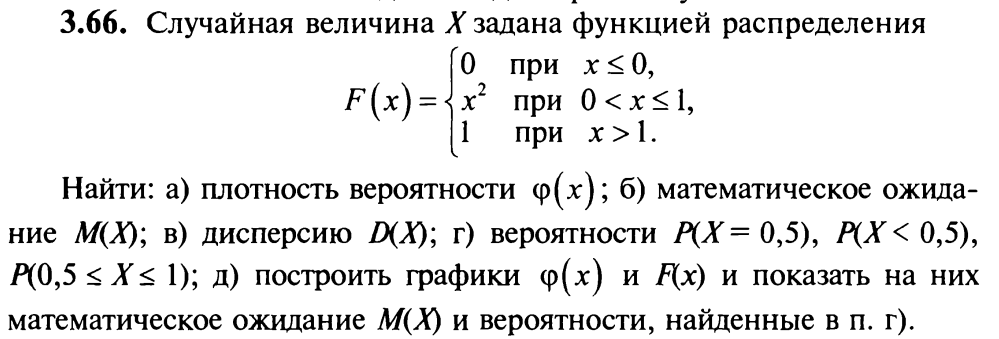
### Решение

а) Интеграл f(x) на [0.0, 1.0] = 1.000000 (ошибка: 1.110223e-14)
б) Математическое ожидание: 0.6667
в) Дисперсия: 0.0556
г) P(X = 0.5) = 0.0000
   P(X < 0.5) = 0.2500
   P(0.5 <= X <= 1) = 0.7500
д)


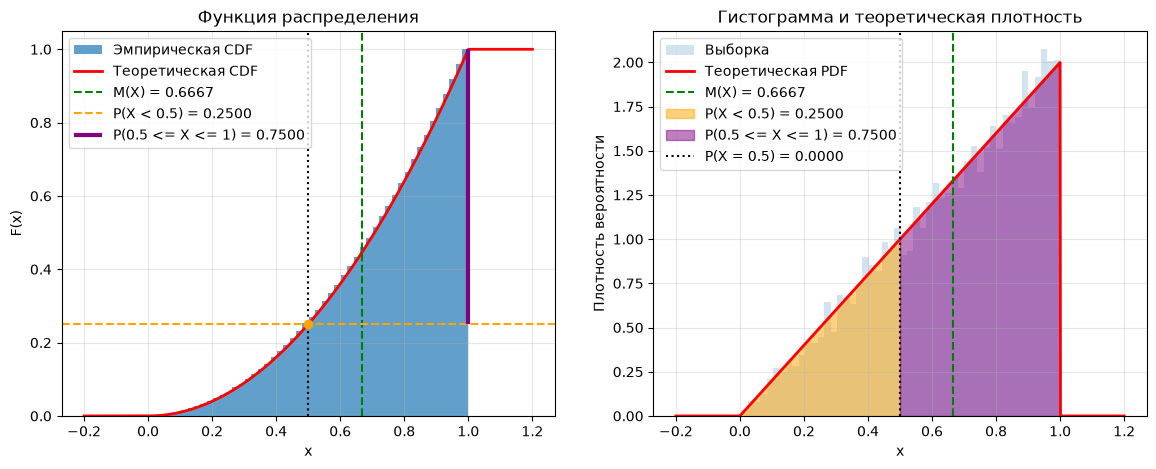

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rv_continuous
from scipy import integrate

class CustomDistribution(rv_continuous):
    def __init__(self, a, b):
        super().__init__(a=a, b=b, name='custom_dist')
    def _cdf(self, x):
        result = np.zeros_like(x)
        result[x <= self.a] = 0
        result[(x > self.a) & (x <= self.b)] = x*x
        result[x > self.b] = 1
        return result
    def _pdf(self, x):
        result = np.zeros_like(x)
        result[(x > self.a) & (x <= self.b)] = 2*x
        result[x > self.b] = 0
        return result
a, b = 0.0, 1.0
custom_dist = CustomDistribution(a, b)
integral, error = integrate.quad(custom_dist.pdf, a, b)
print(f"а) Интеграл f(x) на [{a}, {b}] = {integral:.6f} (ошибка: {error:.6e})")
print(f"б) Математическое ожидание: {custom_dist.mean():.4f}")
print(f"в) Дисперсия: {custom_dist.var():.4f}")
p1 = custom_dist.cdf(0.5) - custom_dist.cdf(0.5)
p2 = custom_dist.cdf(0.5) - custom_dist.cdf(0.0)
p3 = custom_dist.cdf(1.0) - custom_dist.cdf(0.5)
print(f"г) P(X = 0.5) = {p1:.4f}\n"
            f"   P(X < 0.5) = {p2:.4f}\n"
            f"   P(0.5 <= X <= 1) = {p3:.4f}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))
x_plot = np.linspace(a - 0.2, b + 0.2, 1000)
sample = custom_dist.rvs(size = 10000)

mean = custom_dist.mean()

x1 = np.linspace(0, 0.5, 500)[1:]
x2 = np.linspace(0.5, 1, 500)

ax1.hist(sample, bins=50, density=True, cumulative=True, alpha=0.7, label='Эмпирическая CDF')
ax1.plot(x_plot, custom_dist.cdf(x_plot), 'r-', linewidth=2, label='Теоретическая CDF')
ax1.axvline(mean, color='green', linestyle='--',
            label=f'M(X) = {mean:.4f}')
ax1.axvline(0.5, color='black', linestyle=':')
ax1.axhline(p2, color='orange', linestyle='--',
            label=f'P(X < 0.5) = {p2:.4f}')

ax1.scatter(0.5, p2, color='orange', zorder=5)

ax1.vlines(1, p2, 1, color='purple', linewidth=3,
           label=f'P(0.5 <= X <= 1) = {p3:.4f}')

ax1.set_xlabel('x')
ax1.set_ylabel('F(x)')
ax1.set_title('Функция распределения')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.hist(sample, bins=50, density=True, alpha=0.2, label='Выборка')
ax2.plot(x_plot, custom_dist.pdf(x_plot), 'r-', linewidth=2, label='Теоретическая PDF')
ax2.axvline(mean, color='green', linestyle='--',
            label=f'M(X) = {mean:.4f}')

ax2.fill_between(x1, custom_dist.pdf(x1),
                 color='orange', alpha=0.5,
                 label=f'P(X < 0.5) = {p2:.4f}')

ax2.fill_between(x2, custom_dist.pdf(x2),
                 color='purple', alpha=0.5,
                 label=f'P(0.5 <= X <= 1) = {p3:.4f}')

ax2.axvline(0.5, color='black', linestyle=':',
            label=f'P(X = 0.5) = {p1:.4f}')
ax2.set_xlabel('x')
ax2.set_ylabel('Плотность вероятности')
ax2.set_title('Гистограмма и теоретическая плотность')
ax2.legend()
ax2.grid(True, alpha=0.3)
print("д)")
plt.show()

## Задача 3.67
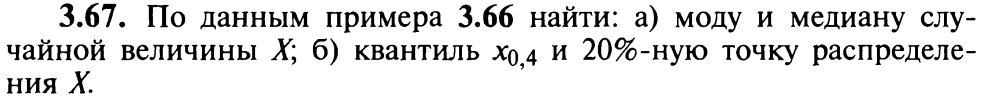
### Решение

In [39]:
x = np.linspace(a, b, 10000)[1:]
mode = x[np.argmax(custom_dist.pdf(x))]
print(f"а) Мода = {mode:.4f}\n"
      f"   Медиана: {custom_dist.median():.4f}")
print(f"б) квантиль 0.4: {custom_dist.ppf(0.4):.4f}\n"
      f"   20%-ная точка: {custom_dist.ppf(0.8):.4f} ")

а) Мода = 1.0000
   Медиана: 0.7071
б) квантиль 0.4: 0.6325
   20%-ная точка: 0.8944 


## Задача 3.68
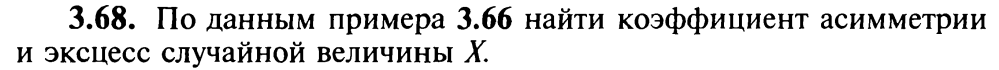
### Решение

In [42]:
print(f"Коэффициент асимметрии: {custom_dist.stats(moments='s'):.4f}, эксцесс: {custom_dist.stats(moments='k'):.4f}")

Коэффициент асимметрии: -0.5657, эксцесс: -0.6000


## Задача 3.69
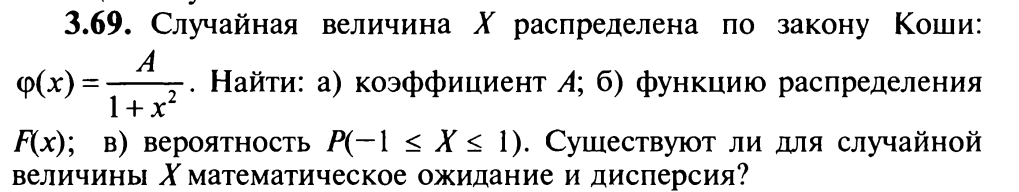
### Решение

In [64]:
from sympy import Symbol, Integral, oo, nan
x = Symbol('x')
expr1 = Integral(1 / (1+x**2), (x, -oo,oo))
A = 1 / expr.doit()
t = Symbol('t')
expr2 = Integral(A / (1+t**2), (t, -oo,x))
F = expr2.doit()
p = F.subs(x, 1) - F.subs(x, -1)
M = Integral(x * A / (1 + x**2), (x, -oo, oo)).doit()
print(f"а) A = {A:.4f}")
print(f"б) F(x) = {F}")
print(f"в) P(-1 <= X <= 1) = {p:.4f}")
if M == nan:
    print("Для случайной величины X математического ожидания и дисперсии не существует")
else:
    D = Integral(x**2 * A / (1 + x**2), (x, -oo, oo)).doit() - M**2
    print(f"M(X) = {M:.4f}")
    print(f"D(X) = {D:.4f}")

а) A = 0.3183
б) F(x) = atan(x)/pi + 1/2
в) P(-1 <= X <= 1) = 0.5000
Для случайной величины X математического ожидания и дисперсии не существует
